# eedi neurips 2020 task 3/4 — cda/cdm data preparation

**tujuan:** membangun assessment item bank dan dataset response yang siap dipakai untuk pipeline **cda → cdm → learning-gap detection**.

pipeline ini melakukan 4 tahap yang sama secara deterministik:

1. **pengumpulan data** — validasi arsip resmi, struktur file, jumlah siswa/soal/interaksi, dan image assets.
2. **preprocessing lanjutan** — cleaning, deduplikasi resmi (latest response per student-question), validasi jawaban, split student-disjoint, normalisasi train-only, imbalance weighting, dan feature engineering.
3. **eda mendalam** — response balance, difficulty, interaction density, option distribution, confidence, temporal volume, concept coverage, dan image audit.
4. **dataset siap latih** — `responses_*.npz`, `q_matrix.csv`, `cda_item_bank.csv`, `interactions_*.csv`, feature metadata, dan manifest.

> **catatan lisensi:** eedi menyatakan question images dibagikan hanya untuk model training dan tidak boleh dicetak atau dibagikan di luar kompetisi. pipeline menyimpan **path gambar**, bukan menyalin byte gambar ke output final.


In [ ]:
# ============================================================
# 0. setup colab
# ============================================================

from pathlib import Path
import os
import sys
import json
import shutil
import zipfile
import urllib.request

# deteksi apakah sedang jalan di google colab
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive

    # mount google drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path("/content/drive/MyDrive/ILCDA")
else:
    # fallback kalau dijalankan lokal
    PROJECT_DIR = Path.cwd() / "ILCDA"

# lokasi dataset dan output
DATA_ZIP = PROJECT_DIR / "data.zip"
OUTPUT_DIR = PROJECT_DIR / "processed_task34_cda_cdm" / "final"

# buat folder project/output
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("environment setup")
print("=" * 60)

print(f"mode        : {'google colab' if IN_COLAB else 'local'}")
print(f"project     : {PROJECT_DIR}")
print(f"data.zip    : {DATA_ZIP}")
print(f"output      : {OUTPUT_DIR}")
print(f"zip exists  : {DATA_ZIP.exists()}")

if DATA_ZIP.exists():
    print(f"zip size    : {DATA_ZIP.stat().st_size / (1024**2):.2f} mb")

Mounted at /content/drive
environment setup
mode        : google colab
project     : /content/drive/MyDrive/ILCDA
data.zip    : /content/drive/MyDrive/ILCDA/data.zip
output      : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/final
zip exists  : False


## 1. pengumpulan data

arsip yang dipakai adalah **public data eedi neurips 2020**, task 3/4. dokumentasi resmi menyatakan dataset task 3/4 berisi **4,918 siswa, 948 pertanyaan, dan 1,382,727 answer records**, plus question images dan metadata.

referensi resmi:
- https://www.eedischool.com/projects/neurips-education-challenge
- https://competitions.codalab.org/competitions/25449


In [ ]:
# ============================================================
# 1. download + validate eedi neurips 2020
# ============================================================

DATA_URL = "https://dqanonymousdata.blob.core.windows.net/neurips-public/data.zip"

def validate_zip(zip_path: Path) -> bool:
    """cek apakah archive zip valid."""
    try:
        with zipfile.ZipFile(zip_path, "r") as z:
            bad = z.testzip()

            if bad is not None:
                print(f"archive rusak. file bermasalah: {bad}")
                return False

            # cek marker penting dari dataset
            names = set(z.namelist())

            has_train = any(
                name.endswith("train_task_3_4.csv")
                for name in names
            )

            has_question = any(
                name.endswith("question_metadata_task_3_4.csv")
                for name in names
            )

            has_student = any(
                name.endswith("student_metadata_task_3_4.csv")
                for name in names
            )

            if not (has_train and has_question and has_student):
                print("archive valid sebagai zip, tapi struktur eedi tidak lengkap.")
                return False

            return True

    except (zipfile.BadZipFile, OSError, EOFError) as e:
        print(f"gagal membaca zip: {e}")
        return False


# ------------------------------------------------------------
# cek apakah dataset sudah ada
# ------------------------------------------------------------

if DATA_ZIP.exists():
    print("=" * 60)
    print("data.zip ditemukan")
    print("=" * 60)

    size_mb = DATA_ZIP.stat().st_size / (1024**2)
    print(f"ukuran: {size_mb:.2f} mb")

    print("\nmemvalidasi archive...")

    if validate_zip(DATA_ZIP):
        print("zip validation: OK")
        print("dataset siap dipakai.")
    else:
        print("archive ternyata rusak / tidak lengkap.")
        print("akan dihapus dan didownload ulang.")

        DATA_ZIP.unlink()

# ------------------------------------------------------------
# download kalau belum ada / invalid
# ------------------------------------------------------------

if not DATA_ZIP.exists():
    print("=" * 60)
    print("download eedi neurips 2020")
    print("=" * 60)

    temp_zip = DATA_ZIP.with_suffix(".part")

    # hapus partial download sebelumnya
    if temp_zip.exists():
        temp_zip.unlink()

    print(f"source : {DATA_URL}")
    print(f"target : {DATA_ZIP}")
    print()
    print("download dimulai...")

    try:
        with urllib.request.urlopen(DATA_URL, timeout=60) as response:
            total = response.headers.get("Content-Length")
            total = int(total) if total else None

            downloaded = 0
            chunk_size = 1024 * 1024  # 1 mb

            with open(temp_zip, "wb") as f:
                while True:
                    chunk = response.read(chunk_size)

                    if not chunk:
                        break

                    f.write(chunk)
                    downloaded += len(chunk)

                    if total:
                        percent = downloaded / total * 100
                        mb = downloaded / (1024**2)
                        total_mb = total / (1024**2)

                        print(
                            f"\rprogress: {percent:6.2f}% "
                            f"({mb:,.1f}/{total_mb:,.1f} mb)",
                            end=""
                        )
                    else:
                        mb = downloaded / (1024**2)
                        print(
                            f"\rdownloaded: {mb:,.1f} mb",
                            end=""
                        )

        print("\n")
        print("download selesai.")

        # pindahkan partial -> final
        temp_zip.replace(DATA_ZIP)

    except Exception as e:
        if temp_zip.exists():
            temp_zip.unlink()

        raise RuntimeError(
            f"download dataset gagal: {e}"
        ) from e

    # --------------------------------------------------------
    # validasi setelah download
    # --------------------------------------------------------

    print("memvalidasi archive hasil download...")

    if not validate_zip(DATA_ZIP):
        DATA_ZIP.unlink(missing_ok=True)
        raise RuntimeError(
            "data.zip berhasil didownload tetapi archive tidak valid."
        )

    print("zip validation: OK")


# ------------------------------------------------------------
# final status
# ------------------------------------------------------------

print("=" * 60)
print("dataset ready")
print("=" * 60)

print(f"path   : {DATA_ZIP}")
print(f"size   : {DATA_ZIP.stat().st_size / (1024**2):.2f} mb")
print(f"output : {OUTPUT_DIR}")

download eedi neurips 2020
source : https://dqanonymousdata.blob.core.windows.net/neurips-public/data.zip
target : /content/drive/MyDrive/ILCDA/data.zip

download dimulai...
progress: 100.00% (626.4/626.4 mb)

download selesai.
memvalidasi archive hasil download...
zip validation: OK
dataset ready
path   : /content/drive/MyDrive/ILCDA/data.zip
size   : 626.36 mb
output : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/final


In [ ]:
# jalankan akuisisi + pipeline penuh
if not DATA_ZIP.exists():
    raise FileNotFoundError(
        f'data.zip tidak ditemukan di {DATA_ZIP}. '
        'upload data.zip ke MyDrive/IL terlebih dahulu.'
    )

result = run_pipeline(DATA_ZIP, OUTPUT_DIR, force_extract=False)
print('\n=== pipeline summary ===')
print(json.dumps(result['summary'], indent=2, ensure_ascii=False))
print('\nall pipeline sanity checks passed')



=== pipeline summary ===
{
  "interactions_final": 1382727,
  "students_final": 4918,
  "questions_final": 948,
  "correct_rate": 0.5373316641679811,
  "answer_option_distribution": {
    "1": 0.24446184966374418,
    "2": 0.2754542292151668,
    "3": 0.27771353275086114,
    "4": 0.2023703883702278
  },
  "students_16_17_proxy": 6,
  "focus_questions": 144,
  "multi_concept_questions": 14,
  "avg_concepts_per_question": 1.0147679324894514,
  "q_matrix_density": 0.017802946184025465,
  "train_correct_rate": 0.5374875275293272,
  "train_class_weights": {
    "0": 1.0810519278087234,
    "1": 0.9302541443116897
  },
  "train_option_weights": {
    "1": 1.0231269267840457,
    "2": 0.9047928114335165,
    "3": 0.9015956325960314,
    "4": 1.2372653260966278
  },
  "official_expected": {
    "students": 4918,
    "questions": 948,
    "interactions": 1382727,
    "images": 948
  },
  "image_audit": {
    "image_dir_exists": true,
    "n_image_files": 948,
    "n_expected_images": 948,
   

## 2. preprocessing audit

hasil utama yang perlu diperiksa:
- data response hanya memiliki `IsCorrect ∈ {0,1}` dan `AnswerValue/CorrectAnswer ∈ {1,2,3,4}`;
- setelah preprocessing, satu `(UserId, QuestionId)` hanya menyisakan response terbaru;
- train/validation/test **student-disjoint**;
- statistik z-score dihitung dari train saja;
- imbalance ditangani dengan class/sample weights, **bukan SMOTE**, agar sequence response tidak dirusak.


In [ ]:
# tampilkan artefak inti
manifest = json.loads((OUTPUT_DIR / 'dataset_manifest.json').read_text(encoding='utf-8'))
eda = json.loads((OUTPUT_DIR / 'eda_summary.json').read_text(encoding='utf-8'))

print('observed:', manifest['observed'])
print('splits:', eda['splits'])
print('binary class weights:', eda['binary_class_weights'])
print('option weights:', eda['option_class_weights'])
print('image audit:', json.dumps(eda['image_audit'], indent=2))


observed: {'students': 4918, 'questions': 948, 'interactions': 1382727}
splits: {'train': 3934, 'val': 492, 'test': 492}
binary class weights: {'0': 1.0810519278087234, '1': 0.9302541443116897}
option weights: {'1': 1.0231269267840457, '2': 0.9047928114335165, '3': 0.9015956325960314, '4': 1.2372653260966278}
image audit: {
  "image_dir_exists": true,
  "n_image_files": 948,
  "n_expected_images": 948,
  "missing_images": [],
  "extra_images": [],
  "bad_image_count": 0,
  "bad_images": []
}


## 3. eda + visual inspection

file PNG hasil EDA berada di `processed_task34_cda_cdm/final/figures/`.

EDA tidak menghapus data hanya karena sebuah soal mudah/sulit; statistik difficulty/entropy dipakai sebagai **feature dan audit**, bukan sebagai label kualitas absolut.


data root: /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data
item 1 | question id: 589
concepts: ["Substitution into Formula"]
attempts: 2141
pass rate: 0.3829985987856142
difficulty: 0.6170014012143858


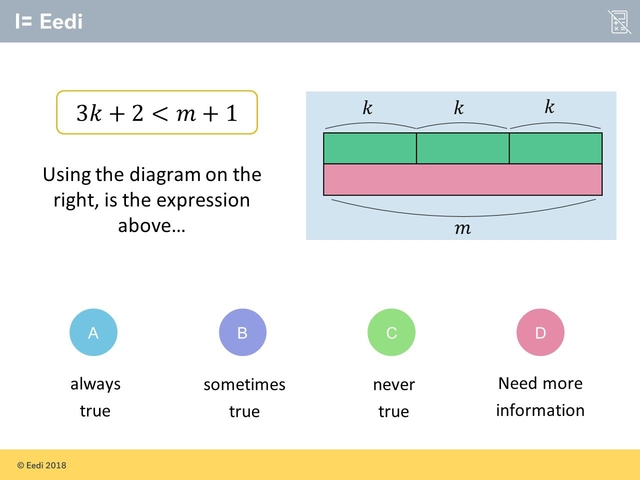

item 2 | question id: 933
concepts: ["Parts of a Circle"]
attempts: 1437
pass rate: 0.7425191370911621
difficulty: 0.2574808629088378


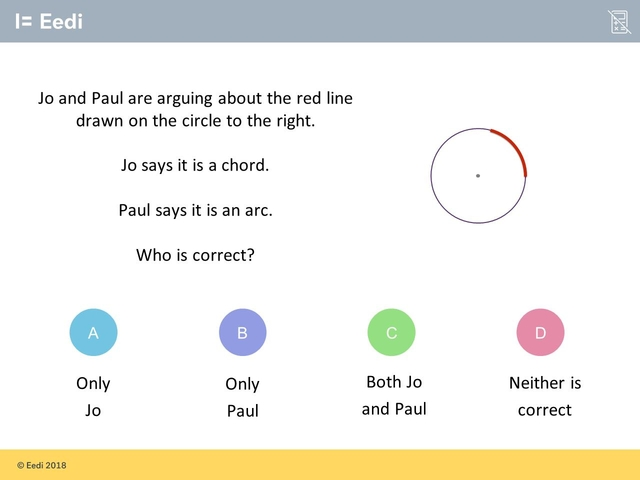

item 3 | question id: 139
concepts: ["Converting between Fractions and Decimals"]
attempts: 6
pass rate: 0.3333333333333333
difficulty: 0.6666666666666667


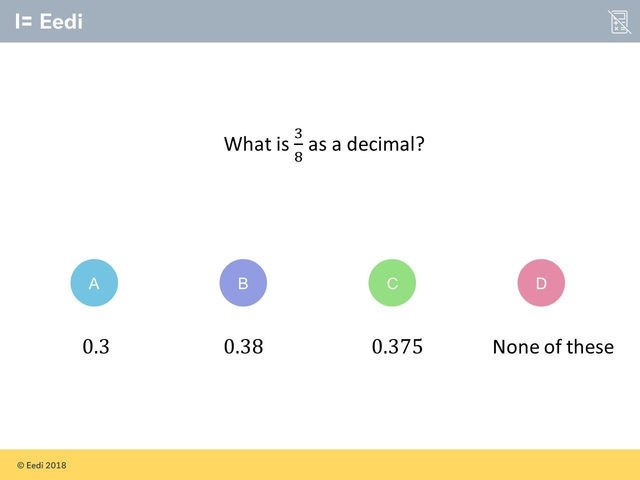

item 4 | question id: 86
concepts: ["Multiples and Lowest Common Multiple"]
attempts: 2185
pass rate: 0.7569794050343249
difficulty: 0.243020594965675


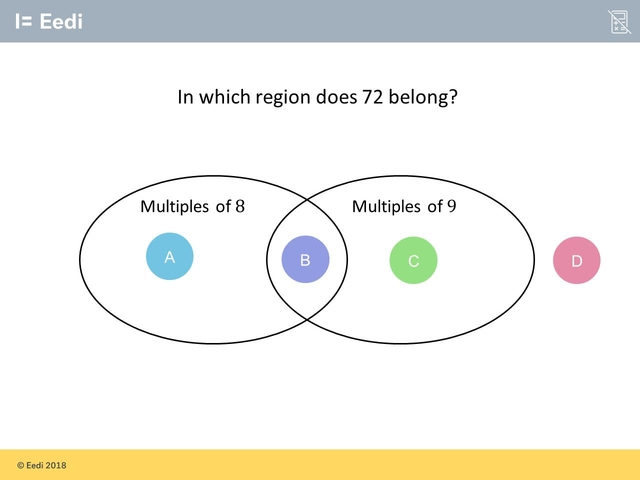

item 5 | question id: 39
concepts: ["Angle Facts with Parallel Lines"]
attempts: 2607
pass rate: 0.4560797851937092
difficulty: 0.5439202148062907


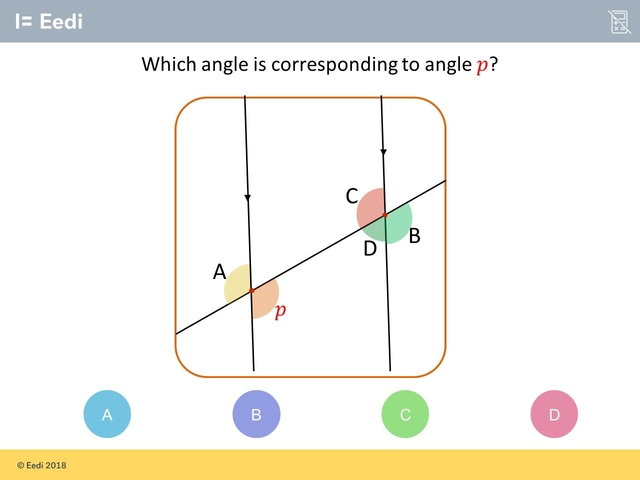

In [ ]:
# tampilkan 5 diagnostic items acak dari item bank
import random
from IPython.display import display, Image, Markdown

bank = pd.read_csv(OUTPUT_DIR / 'cda_item_bank.csv')
rng = np.random.default_rng(42)
rows = bank.sample(n=min(5, len(bank)), random_state=42)

# cari root data setelah ekstraksi
root = Path(manifest['data_root'])
print('data root:', root)

for i, row in enumerate(rows.itertuples(), 1):
    qid = int(row.QuestionId)
    print('=' * 90)
    print(f'item {i} | question id: {qid}')
    print('concepts:', row.concept_names)
    print('attempts:', getattr(row, 'n_attempts', None))
    print('pass rate:', getattr(row, 'pass_rate', None))
    print('difficulty:', getattr(row, 'difficulty', None))
    image_path = root / 'images' / f'{qid}.jpg'
    if image_path.exists():
        display(Image(filename=str(image_path)))
    else:
        print('image tidak ditemukan:', image_path)


image directory: /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images
exists: True

question id : 818
topics      : ['Naming Co-ordinates in 2D', 'Maths', 'Algebra', 'Co-ordinates']
difficulty  : 0.7835
pass rate   : 0.2165
attempts    : 1155
correct     : 2
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/818.jpg


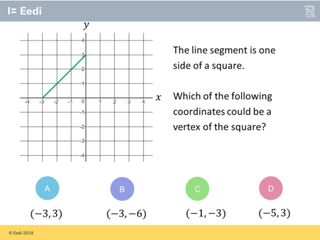


question id : 856
topics      : ['Writing Expressions', 'Maths', 'Algebra', 'Writing and Simplifying Expressions']
difficulty  : 0.7283
pass rate   : 0.2717
attempts    : 2900
correct     : 3
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/856.jpg


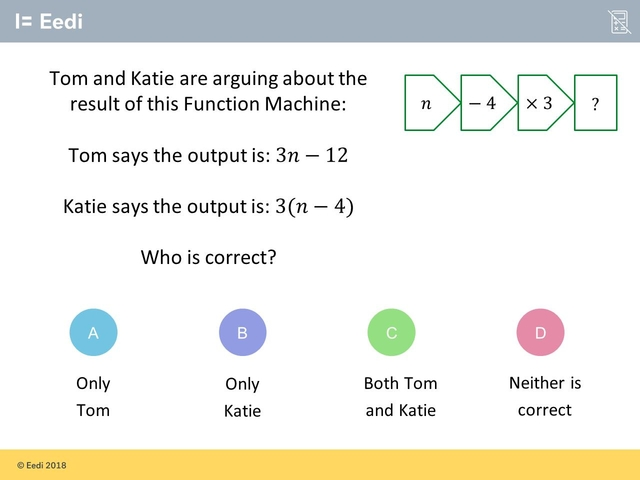


question id : 142
topics      : ['Substitution into Formula', 'Maths', 'Algebra', 'Formula']
difficulty  : 0.7281
pass rate   : 0.2719
attempts    : 2457
correct     : 2
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/142.jpg


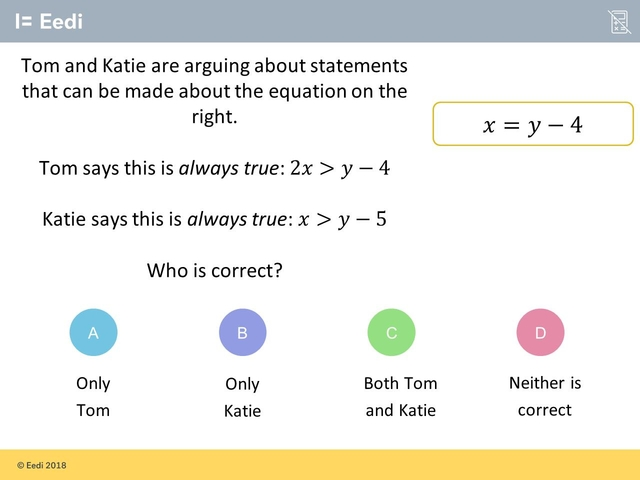


question id : 110
topics      : ['Naming Co-ordinates in 2D', 'Maths', 'Algebra', 'Co-ordinates']
difficulty  : 0.7273
pass rate   : 0.2727
attempts    : 1155
correct     : 1
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/110.jpg


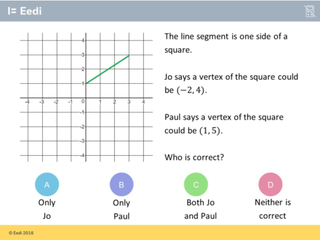


question id : 762
topics      : ['Naming Co-ordinates in 2D', 'Maths', 'Algebra', 'Co-ordinates']
difficulty  : 0.7134
pass rate   : 0.2866
attempts    : 1884
correct     : 3
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/762.jpg


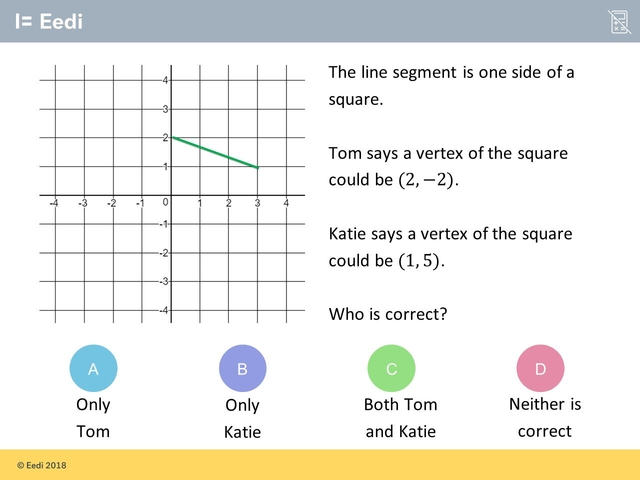


question id : 611
topics      : ['Writing Expressions', 'Maths', 'Algebra', 'Writing and Simplifying Expressions']
difficulty  : 0.7057
pass rate   : 0.2943
attempts    : 2280
correct     : 2
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/611.jpg


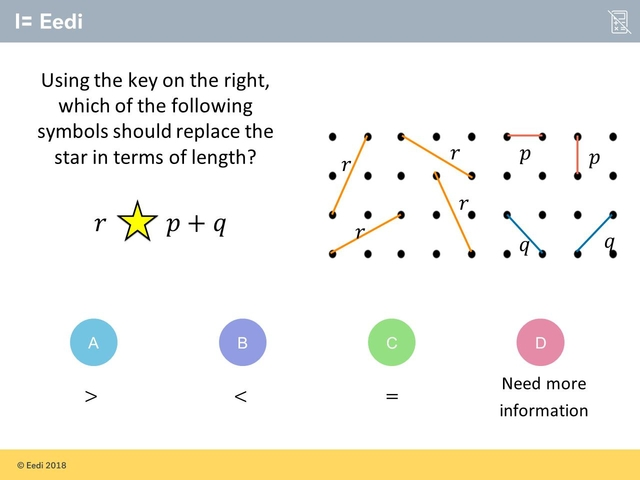


question id : 709
topics      : ['Substitution into Formula', 'Maths', 'Algebra', 'Formula']
difficulty  : 0.7026
pass rate   : 0.2974
attempts    : 2135
correct     : 1
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/709.jpg


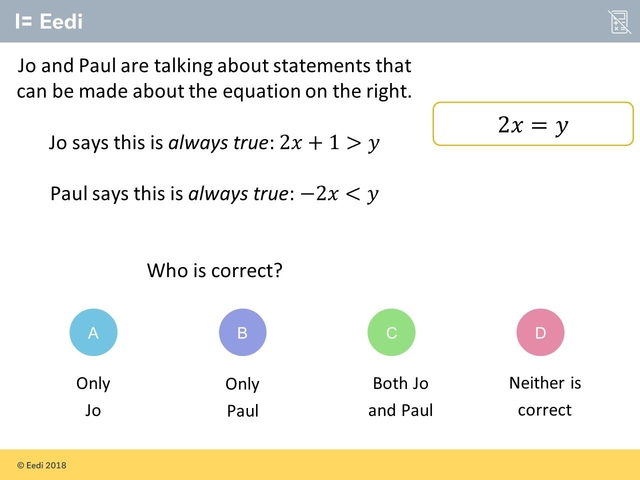


question id : 230
topics      : ['Solving Linear Inequalities', 'Maths', 'Algebra', 'Inequalities']
difficulty  : 0.7000
pass rate   : 0.3000
attempts    : 1500
correct     : 1
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/230.jpg


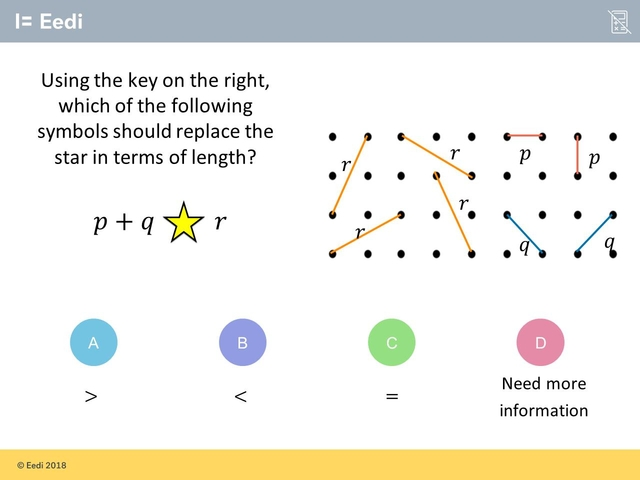


question id : 63
topics      : ['Midpoint Between Two Co-ordinates', 'Maths', 'Algebra', 'Co-ordinates']
difficulty  : 0.6910
pass rate   : 0.3090
attempts    : 1178
correct     : 4
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/63.jpg


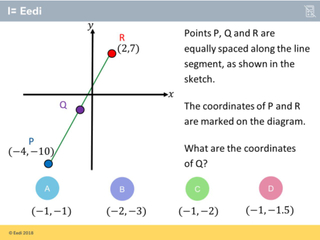


question id : 641
topics      : ['Horizontal and Vertical Lines', 'Maths', 'Algebra', 'Straight Line Graphs']
difficulty  : 0.6876
pass rate   : 0.3124
attempts    : 1575
correct     : 3
image       : /content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/eedi_task34_extracted/data/images/641.jpg


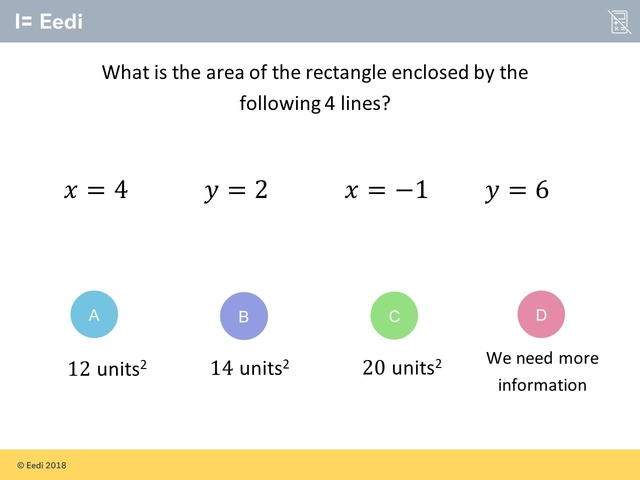

In [ ]:
# ============================================================
# tampilkan gambar soal tersulit
# ============================================================

from pathlib import Path
from IPython.display import display, Image

# root dataset hasil extraction
if "result" in globals() and "root" in result:
    DATA_ROOT = Path(result["root"])
else:
    DATA_ROOT = OUTPUT_DIR.parent / "eedi_task34_extracted"

IMAGE_DIR = DATA_ROOT / "images"

print("image directory:", IMAGE_DIR)
print("exists:", IMAGE_DIR.exists())
print()

# jumlah soal yang mau ditampilkan
N = 10

sample = hardest.head(N)

for _, row in sample.iterrows():

    qid = int(row["QuestionId"])
    image_path = IMAGE_DIR / f"{qid}.jpg"

    print("=" * 90)
    print(f"question id : {qid}")
    print(f"topics      : {row['all_topics']}")
    print(f"difficulty  : {row['difficulty']:.4f}")
    print(f"pass rate   : {row['pass_rate']:.4f}")
    print(f"attempts    : {int(row['n_attempts'])}")
    print(f"correct     : {int(row['correct_answer'])}")
    print(f"image       : {image_path}")

    if image_path.exists():
        display(
            Image(
                filename=str(image_path),
                width=800
            )
        )
    else:
        print("❌ gambar tidak ditemukan")

    print()

## 4. dataset siap latih

untuk cdm, artefak paling penting adalah:

```text
q_matrix.csv
concept_metadata.csv
responses_train.npz
responses_val.npz
responses_test.npz
```

untuk cda/item delivery:

```text
cda_item_bank.csv
```

yang terakhir berisi question id, concept mapping, difficulty/statistics dari training data, dan relative image path.


In [ ]:
# inspeksi shape dan beberapa baris output final
qm = pd.read_csv(OUTPUT_DIR / 'q_matrix.csv')
items = pd.read_csv(OUTPUT_DIR / 'cda_item_bank.csv')
train_interactions = pd.read_csv(OUTPUT_DIR / 'interactions_train.csv', nrows=5)

with np.load(OUTPUT_DIR / 'responses_train.npz') as z:
    print('responses_train matrix shape:', z['matrix'].shape)
    print('train users:', z['user_ids'].shape)

print('q_matrix shape:', qm.shape)
print('item bank shape:', items.shape)
display(items.head(10))
display(train_interactions)


responses_train matrix shape: (3934, 948)
train users: (3934,)
q_matrix shape: (948, 58)
item bank shape: (948, 18)


,QuestionId,is_focus,concept_names,concept_count,image_path,n_attempts,pass_rate,mean_confidence,option_entropy,correct_answer_nunique,correct_answer,option_1_rate,option_2_rate,option_3_rate,option_4_rate,difficulty,correct_answer_consistent,has_image
0,0,False,"[""Squares, Cubes, etc""]",1,images/0.jpg,2812,0.443457,66.176471,1.723236,1,1,0.443457,0.350640,0.116287,0.089616,0.556543,True,True
1,1,False,"[""Ordering Fractions""]",1,images/1.jpg,14,0.571429,NaN,1.263809,1,3,0.000000,0.357143,0.571429,0.071429,0.428571,True,True
2,2,False,"[""BIDMAS"", ""Multiplying and Dividing Negative ...",2,images/2.jpg,2313,0.385214,66.201354,1.921184,1,2,0.236057,0.385214,0.225249,0.153480,0.614786,True,True
3,3,False,"[""Adding and Subtracting Negative Numbers""]",1,images/3.jpg,2672,0.808757,85.021246,1.003283,1,2,0.049027,0.808757,0.072605,0.069611,0.191243,True,True
4,4,False,"[""Properties of Quadrilaterals""]",1,images/4.jpg,1704,0.401408,59.343434,1.910592,1,3,0.178991,0.176643,0.401408,0.242958,0.598592,True,True
5,5,False,"[""Area of Simple Shapes""]",1,images/5.jpg,833,0.190876,77.419355,1.676709,1,4,0.100840,0.153661,0.554622,0.190876,0.809124,True,True
6,6,False,"[""Mental Multiplication and Division""]",1,images/6.jpg,1718,0.528522,78.383978,1.743483,1,2,0.149010,0.528522,0.150757,0.171711,0.471478,True,True
7,7,False,"[""Prime Numbers and Prime Factors""]",1,images/7.jpg,89,0.348315,58.823529,1.933927,1,2,0.280899,0.348315,0.224719,0.146067,0.651685,True,True
8,8,False,"[""Factors and Highest Common Factor""]",1,images/8.jpg,2327,0.391921,69.196429,1.888364,1,1,0.391921,0.131070,0.282768,0.194242,0.608079,True,True
9,9,False,"[""Area of Simple Shapes""]",1,images/9.jpg,834,0.363309,76.219512,1.832424,1,3,0.166667,0.365707,0.363309,0.104317,0.636691,True,True


,UserId,QuestionId,AnswerId,IsCorrect,CorrectAnswer,AnswerValue,DateAnswered,Confidence,GroupId,QuizId,...,student_mean_confidence,prior_accuracy,confidence_norm_z,time_since_prev_sec_log1p_z,elapsed_days_log1p_z,question_pass_rate_z,question_difficulty_z,prior_accuracy_z,age_years_z,split
0,1,182,1181805,0,3,2,2019-10-11 13:15:00,NaN,251,75,...,35.483871,NaN,NaN,NaN,-1.648449,-1.801357,1.801357,NaN,NaN,train
1,1,202,287821,0,1,2,2019-10-11 13:17:00,50.0,251,75,...,35.483871,0.000000,-0.757411,0.642173,-1.648386,1.568383,-1.568383,-2.822287,NaN,train
2,1,420,925509,1,2,2,2019-10-11 13:17:00,50.0,251,75,...,35.483871,0.000000,-0.757411,-0.850780,-1.648386,1.501016,-1.501016,-2.822287,NaN,train
3,1,403,1192500,1,3,3,2019-10-11 13:18:00,50.0,251,75,...,35.483871,0.333333,-0.757411,0.428955,-1.648354,0.770367,-0.770367,-1.183906,NaN,train
4,1,691,522876,1,3,3,2019-10-11 13:19:00,50.0,251,75,...,35.483871,0.500000,-0.757411,0.428955,-1.648322,0.791008,-0.791008,-0.364716,NaN,train


In [ ]:
# final sanity checks yang harus tetap true setelah semua proses
assert qm['QuestionId'].is_unique
assert set(qm.drop(columns=['QuestionId']).stack().unique()).issubset({0,1})
assert set(items['QuestionId']) == set(qm['QuestionId'])
assert items['has_image'].all() or (items['image_path'].str.len() > 0).all()

inter_train = pd.read_csv(OUTPUT_DIR / 'interactions_train.csv', usecols=['UserId','QuestionId','IsCorrect','AnswerValue'])
assert inter_train['IsCorrect'].isin([0,1]).all()
assert inter_train['AnswerValue'].isin([1,2,3,4]).all()

print('all final sanity checks passed')


all final sanity checks passed
